In [1]:
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 40.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 4.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
import os, gc, time, json, urllib.request
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

sns.set_theme(style='whitegrid')
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0 | GPU: []


2026-10-08 06:10:11.894811: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [3]:
DATASET_PATH = "/kaggle/input/datasets/navneet0094/n-da-ja/jaffe"

PRETRAINED   = True     # ImageNet weights 
FACE_SIZE    = 224      # whole-face image size
REGION_SIZE  = 128      # eyes / nose / mouth crop size

# ---- Part A ----
FIRST_FROZEN   = 10                    # first 10 conv layers are never trained
LAYER_SETTINGS = [0, 5, 10, 15, 20]    # N = number of LAST conv layers to fine-tune (0 = only the new head)
FORCE_N        = None                  # None = pick N automatically (best validation). Or write a number, e.g. 15

# ---- training ----
N_SPLITS        = 3     # how many different train/val/test splits to repeat on (use 5 for the final report)
BATCH_SIZE      = 16
WARMUP_EPOCHS   = 20    # stage 1: backbone frozen, train only the new head
WARMUP_LR       = 1e-3
FINETUNE_EPOCHS = 40    # stage 2: unfreeze last N layers
FINETUNE_LR     = 5e-5
SEED            = 42

EMOTION_MAP = {'AN':0,'DI':1,'FE':2,'HA':3,'SA':4,'SU':5,'NE':6}
CLASS_NAMES = ['Anger','Disgust','Fear','Happy','Sadness','Surprise','Neutral']
REGIONS     = ['eyes', 'nose', 'mouth']
COND_NAMES  = ['Clean', 'Eyes hidden', 'Nose hidden', 'Mouth hidden']

In [4]:

raw_images, labels, persons = [], [], []
for name in sorted(os.listdir(DATASET_PATH)):
    parts = name.split('.')
    if len(parts) < 3 or parts[1][:2] not in EMOTION_MAP:
        continue
    raw_images.append(np.array(Image.open(os.path.join(DATASET_PATH, name)).convert('RGB')))
    labels.append(EMOTION_MAP[parts[1][:2]]); persons.append(parts[0])
y = np.array(labels); persons = np.array(persons)
print('Images:', len(raw_images), '| persons:', len(set(persons)), '| emotions:', len(CLASS_NAMES))

Images: 213 | persons: 10 | emotions: 7


In [5]:
# ---------- 1b. start the MediaPipe face landmark model ----------
import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

MODEL_FILE = 'face_landmarker.task'
URL = 'https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task'
landmarker = None
try:
    if not os.path.exists(MODEL_FILE):
        urllib.request.urlretrieve(URL, MODEL_FILE)         
    landmarker = vision.FaceLandmarker.create_from_options(
        vision.FaceLandmarkerOptions(base_options=BaseOptions(model_asset_path=MODEL_FILE), num_faces=1))
    print('MediaPipe Face Landmarker is ready.')
except Exception as e:
    print('!! MediaPipe could not start:', type(e).__name__, '- using fixed boxes instead. (Turn Internet ON and re-run to use landmarks.)')

def get_landmarks(img):
    # returns 468 (x, y) points in pixels, or None if no face found
    if landmarker is None:
        return None
    res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img)))
    if not res.face_landmarks:
        return None
    h, w = img.shape[:2]
    return np.array([[p.x * w, p.y * h] for p in res.face_landmarks[0]], dtype=np.float32)

MediaPipe Face Landmarker is ready.


W0000 00:00:1791439814.487801     154 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791439814.503400     158 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791439814.532666     158 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [6]:
# ---------- 1c. align the face + compute eyes/nose/mouth boxes from landmarks ----------
EYE_A, EYE_B = 33, 263        # outer corners of the two eyes (used to make the eyes level)
LM_GROUPS = {                 # which landmark points belong to each region
    'eyes':  [33,7,163,144,145,153,154,155,133,173,157,158,159,160,161,246, 362,382,381,380,374,373,390,249,263,466,388,387,386,385,384,398,
              70,63,105,66,107,55,65,52,53,46,300,293,334,296,336,285,295,282,283,276],      # both eyes + eyebrows
    'nose':  [197,195,5,4,1,19,94,2,98,97,326,327,129,358,49,279,48,278,64,294,219,439],
    'mouth': [61,146,91,181,84,17,314,405,321,375,291,409,270,269,267,0,37,39,40,185,
              78,95,88,178,87,14,317,402,318,324,308,415,310,311,312,13,82,81,80,191],
}


def align_and_crop(img, lm, size=FACE_SIZE, margin=0.25):
    h, w = img.shape[:2]
    a, b = lm[EYE_A], lm[EYE_B]
    angle = np.degrees(np.arctan2(b[1] - a[1], b[0] - a[0]))                  # tilt of the eye line
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    rotated = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    pts = np.hstack([lm, np.ones((len(lm), 1), np.float32)]) @ M.T           # rotate landmarks the same way
    x0, y0 = pts.min(0); x1, y1 = pts.max(0)
    bw, bh = x1 - x0, y1 - y0
    x0, y0 = int(max(0, x0 - bw * margin)), int(max(0, y0 - bh * margin))
    x1, y1 = int(min(w, x1 + bw * margin)), int(min(h, y1 + bh * margin))
    if x1 - x0 < 10 or y1 - y0 < 10:
        return None, None
    face = cv2.resize(rotated[y0:y1, x0:x1], (size, size), interpolation=cv2.INTER_AREA)
    pts = (pts - [x0, y0]) * [size / (x1 - x0), size / (y1 - y0)]            # landmarks in the new face coordinates
    return face, pts.astype(np.float32)

def boxes_from_landmarks(pts, size=FACE_SIZE, pad=0.15, min_size=24):
    out = []
    for r in REGIONS:
        p = pts[LM_GROUPS[r]]
        x0, y0 = p.min(0); x1, y1 = p.max(0)
        px, py = (x1 - x0) * pad, (y1 - y0) * pad
        x0, y0, x1, y1 = x0 - px, y0 - py, x1 + px, y1 + py
        if x1 - x0 < min_size: c = (x0 + x1) / 2; x0, x1 = c - min_size / 2, c + min_size / 2
        if y1 - y0 < min_size: c = (y0 + y1) / 2; y0, y1 = c - min_size / 2, c + min_size / 2
        out.append([max(0, int(x0)), max(0, int(y0)), min(size, int(x1)), min(size, int(y1))])
    return np.array(out)

def fixed_boxes(size=FACE_SIZE):             # backup if no landmarks: eyes / nose / mouth at typical positions
    f = lambda a, b, c, d: [int(a * size), int(b * size), int(c * size), int(d * size)]
    return np.array([f(.10, .15, .90, .45), f(.30, .40, .70, .70), f(.25, .62, .75, .92)])

faces, boxes, detected = [], [], 0
for img in raw_images:
    face = pts = None
    lm = get_landmarks(img)
    if lm is not None:
        face, pts = align_and_crop(img, lm)
    if face is None:
        faces.append(cv2.resize(img, (FACE_SIZE, FACE_SIZE), interpolation=cv2.INTER_AREA)); boxes.append(fixed_boxes())
    else:
        faces.append(face); boxes.append(boxes_from_landmarks(pts)); detected += 1
faces = np.array(faces, dtype=np.uint8); boxes = np.array(boxes)
print(f'faces: {faces.shape} | landmarks found on {detected} of {len(faces)} images')

# cut the three regions out of every face
def crop_region(face, box):
    x0, y0, x1, y1 = box
    patch = face[y0:y1, x0:x1]
    return cv2.resize(patch if patch.size else face, (REGION_SIZE, REGION_SIZE), interpolation=cv2.INTER_AREA)
crops = np.array([[crop_region(faces[i], boxes[i, k]) for k in range(3)] for i in range(len(faces))], dtype=np.uint8)
print('region crops:', crops.shape, '= (images, 3 regions, height, width, colour)')
del raw_images; gc.collect()

faces: (213, 224, 224, 3) | landmarks found on 213 of 213 images
region crops: (213, 3, 128, 128, 3) = (images, 3 regions, height, width, colour)


424

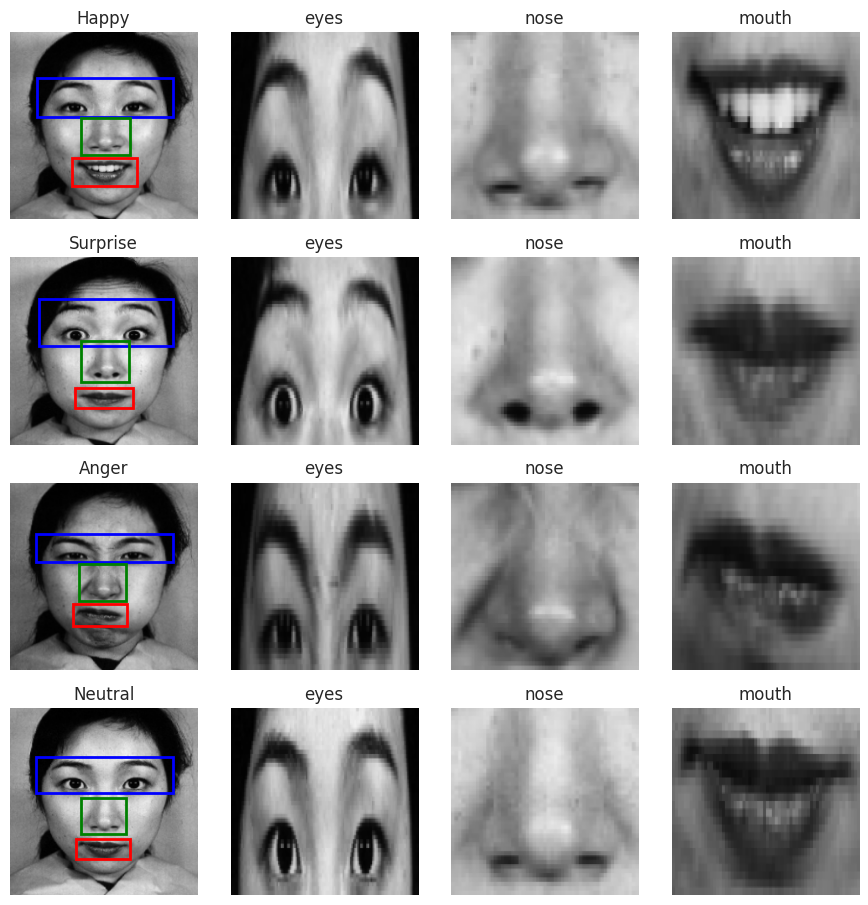

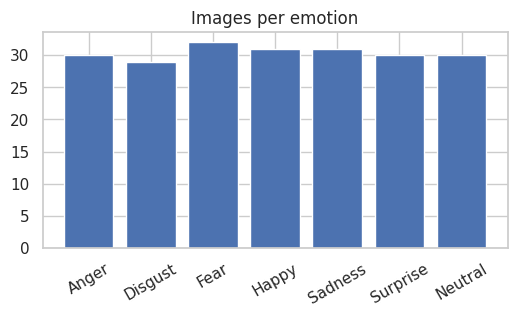

In [7]:
colors = {'eyes': 'blue', 'nose': 'green', 'mouth': 'red'}
show = [np.where(y == c)[0][0] for c in [3, 5, 0, 6]]                      # Happy, Surprise, Anger, Neutral
fig, ax = plt.subplots(len(show), 4, figsize=(9, 2.3 * len(show)))
for r, i in enumerate(show):
    ax[r, 0].imshow(faces[i])
    for k, name in enumerate(REGIONS):
        x0, y0, x1, y1 = boxes[i, k]
        ax[r, 0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=colors[name], lw=2))
        ax[r, k + 1].imshow(crops[i, k]); ax[r, k + 1].set_title(name)
    ax[r, 0].set_title(CLASS_NAMES[y[i]])
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 2.8)); plt.bar(CLASS_NAMES, np.bincount(y)); plt.title('Images per emotion'); plt.xticks(rotation=30); plt.show()

In [8]:
def make_split(seed):
    idx = np.arange(len(y))
    a, b = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(idx, y, persons))
    trainval, test = idx[a], idx[b]
    a, b = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(trainval, y[trainval], persons[trainval]))
    return trainval[a], trainval[b], test

tr, va, te = make_split(SEED)
print('train:', len(tr), '| validation:', len(va), '| test:', len(te))
print('test persons:', sorted(set(persons[te])))
assert not set(persons[tr]) & set(persons[te])
print('JAFFE has only ~10 people, so one test set = ~2 people. Results are noisy, so we repeat on', N_SPLITS, 'splits.')

train: 128 | validation: 42 | test: 43
test persons: [np.str_('KL'), np.str_('UY')]
JAFFE has only ~10 people, so one test set = ~2 people. Results are noisy, so we repeat on 3 splits.


In [9]:
CONV = (layers.Conv2D, layers.DepthwiseConv2D)
probe = MobileNetV2(input_shape=(FACE_SIZE, FACE_SIZE, 3), include_top=False, weights=None)
conv_layers = [l for l in probe.layers if isinstance(l, CONV)]
print('All Keras layers      :', len(probe.layers))
print('Convolution layers    :', len(conv_layers), ' (+1 classifier = 53, the number on Google)')
print('First conv layer      :', conv_layers[0].name)
print('Last conv layer       :', conv_layers[-1].name)
assert max(LAYER_SETTINGS) <= len(conv_layers) - FIRST_FROZEN

All Keras layers      : 154
Convolution layers    : 52  (+1 classifier = 53, the number on Google)
First conv layer      : Conv1
Last conv layer       : Conv_1


In [10]:
def build_model(size):
    backbone = MobileNetV2(input_shape=(size, size, 3), include_top=False, weights='imagenet' if PRETRAINED else None)
    inputs = keras.Input((size, size, 3))
    x = layers.RandomFlip('horizontal')(inputs)          # augmentation (only active while training)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)        # pixels 0..255  ->  -1..1
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
    return keras.Model(inputs, outputs), backbone
    

def set_trainable(backbone, n_last):
    if n_last == 0:
        backbone.trainable = False; return
    backbone.trainable = True
    convs = [l for l in backbone.layers if isinstance(l, CONV)]
    start = backbone.layers.index(convs[-n_last])
    for i, layer in enumerate(backbone.layers):
        layer.trainable = (i >= start) and not isinstance(layer, layers.BatchNormalization)

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def count_trainable(model): return int(sum(np.prod(w.shape) for w in model.trainable_weights))
def stop(patience):         return keras.callbacks.EarlyStopping('val_loss', patience=patience, restore_best_weights=True)

model, backbone = build_model(FACE_SIZE)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 2,388,743 (9.11 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [11]:
# check: does freezing really work?  (trainable parameters must grow with N)
convs = [l for l in backbone.layers if isinstance(l, CONV)]
rows = []
for n in LAYER_SETTINGS:
    set_trainable(backbone, n)
    rows.append({'N': n, 'first trained conv layer': convs[-n].name if n else 'none (backbone frozen)',
                 'trainable params': count_trainable(model), 'total params': model.count_params()})
display(pd.DataFrame(rows))

,N,first trained conv layer,trainable params,total params
0,0,none (backbone frozen),164871,2422855
1,5,block_15_project,1197511,2422855
2,10,block_14_expand,1675591,2422855
3,15,block_12_depthwise,1888711,2422855
4,20,block_10_project,2096647,2422855


In [12]:
def get_mflops(model):
    macs = 0
    for l in model.layers:
        sub = l.layers if isinstance(l, keras.Model) else [l]          # look inside the MobileNetV2 block
        for s in sub:
            if isinstance(s, layers.DepthwiseConv2D):
                h, w = s.output.shape[1:3]; kh, kw, cin, m = s.kernel.shape; macs += h * w * kh * kw * cin * m
            elif isinstance(s, layers.Conv2D):
                h, w = s.output.shape[1:3]; kh, kw, cin, cout = s.kernel.shape; macs += h * w * kh * kw * cin * cout
            elif isinstance(s, layers.Dense):
                macs += s.kernel.shape[0] * s.kernel.shape[1]
    return 2 * macs / 1e6

def get_infer_ms(model, images):
    f = tf.function(lambda x: model(x, training=False))
    one = tf.constant(images[:1].astype('float32'))
    for _ in range(10): f(one).numpy()                                   # warm-up
    t = []
    for _ in range(100):
        s = time.perf_counter(); f(one).numpy(); t.append(time.perf_counter() - s)
    return float(np.median(t) * 1000)

print('Whole-face model:', round(get_mflops(model), 1), 'MFLOPs per image (MobileNetV2 @224px should be ~600)')

Whole-face model: 599.3 MFLOPs per image (MobileNetV2 @224px should be ~600)


---- Stage 1: backbone frozen, train the head ----
Epoch 1/20
8/8 - 14s - 2s/step - accuracy: 0.1016 - loss: 2.3759 - val_accuracy: 0.1429 - val_loss: 1.9590
Epoch 2/20
8/8 - 5s - 649ms/step - accuracy: 0.1719 - loss: 1.9861 - val_accuracy: 0.2857 - val_loss: 1.8133
Epoch 3/20
8/8 - 5s - 651ms/step - accuracy: 0.2578 - loss: 1.9193 - val_accuracy: 0.2857 - val_loss: 1.7548
Epoch 4/20
8/8 - 5s - 635ms/step - accuracy: 0.2734 - loss: 1.7382 - val_accuracy: 0.2619 - val_loss: 1.7176
Epoch 5/20
8/8 - 5s - 640ms/step - accuracy: 0.4141 - loss: 1.6255 - val_accuracy: 0.2381 - val_loss: 1.6799
Epoch 6/20
8/8 - 5s - 667ms/step - accuracy: 0.4297 - loss: 1.6536 - val_accuracy: 0.3571 - val_loss: 1.6250
Epoch 7/20
8/8 - 5s - 594ms/step - accuracy: 0.4453 - loss: 1.4632 - val_accuracy: 0.3333 - val_loss: 1.5293
Epoch 8/20
8/8 - 5s - 621ms/step - accuracy: 0.4609 - loss: 1.4148 - val_accuracy: 0.5238 - val_loss: 1.4581
Epoch 9/20
8/8 - 5s - 586ms/step - accuracy: 0.5234 - loss: 1.3142 - val_accura

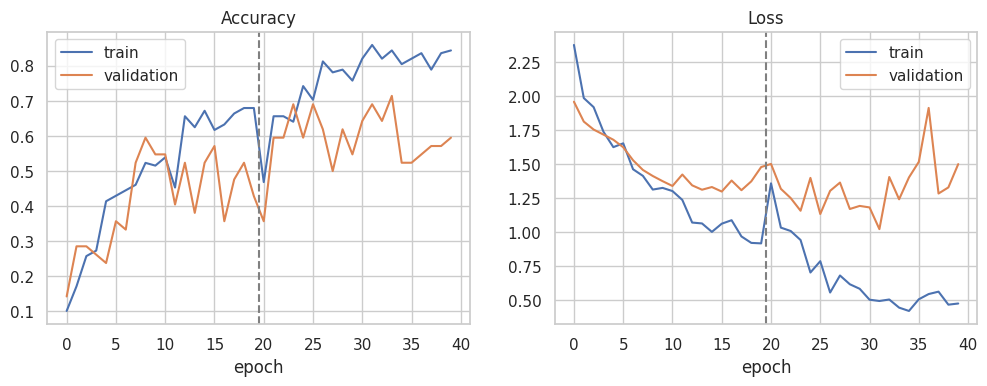

Test accuracy of this one model: 30.2 %


In [13]:
Xtr, ytr, Xva, yva, Xte, yte = faces[tr].astype('float32'), y[tr], faces[va].astype('float32'), y[va], faces[te].astype('float32'), y[te]
keras.utils.set_random_seed(SEED)
model, backbone = build_model(FACE_SIZE)

print('---- Stage 1: backbone frozen, train the head ----')
set_trainable(backbone, 0); compile_model(model, WARMUP_LR)
h1 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=WARMUP_EPOCHS, batch_size=BATCH_SIZE, verbose=2, callbacks=[stop(5)])
print('\n---- Stage 2: unfreeze last 10 conv layers ----')
set_trainable(backbone, 10); compile_model(model, FINETUNE_LR)
h2 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=FINETUNE_EPOCHS, batch_size=BATCH_SIZE, verbose=2, callbacks=[stop(8)])

H = {k: h1.history[k] + h2.history[k] for k in h1.history}; sw = len(h1.history['loss'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(H['accuracy'], label='train'); ax[0].plot(H['val_accuracy'], label='validation'); ax[0].set_title('Accuracy')
ax[1].plot(H['loss'], label='train'); ax[1].plot(H['val_loss'], label='validation'); ax[1].set_title('Loss')
for a in ax: a.axvline(sw - 0.5, color='gray', ls='--'); a.set_xlabel('epoch'); a.legend()
plt.show()
print('Test accuracy of this one model:', round(accuracy_score(yte, model.predict(Xte, verbose=0).argmax(1)) * 100, 1), '%')

In [14]:
sweep, sweep_preds = [], {}
for s in range(N_SPLITS):
    seed = SEED + s; tr, va, te = make_split(seed)
    Xtr, ytr, Xva, yva, Xte, yte = faces[tr].astype('float32'), y[tr], faces[va].astype('float32'), y[va], faces[te].astype('float32'), y[te]
    gc.collect(); keras.utils.set_random_seed(seed)
    model, backbone = build_model(FACE_SIZE)
    set_trainable(backbone, 0); compile_model(model, WARMUP_LR)
    model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=WARMUP_EPOCHS, batch_size=BATCH_SIZE, verbose=0, callbacks=[stop(5)])
    head_weights = model.get_weights()
    print(f'\n=== split {s + 1}/{N_SPLITS} | test persons: {sorted(set(persons[te]))} ===')
    for n in LAYER_SETTINGS:
        model.set_weights(head_weights); keras.utils.set_random_seed(seed)
        set_trainable(backbone, n); compile_model(model, FINETUNE_LR)
        t0 = time.time()
        if n > 0:
            model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=FINETUNE_EPOCHS, batch_size=BATCH_SIZE, verbose=0, callbacks=[stop(8)])
        t_ft = time.time() - t0
        pred = model.predict(Xte, verbose=0).argmax(1); sweep_preds[(s, n)] = (yte, pred)
        sweep.append(dict(split=s, N=n, trainable_params=count_trainable(model),
                          val_acc=model.evaluate(Xva, yva, verbose=0)[1] * 100, test_acc=accuracy_score(yte, pred) * 100,
                          test_f1=f1_score(yte, pred, average='macro') * 100, finetune_time_s=t_ft,
                          infer_ms=get_infer_ms(model, Xte), mflops=get_mflops(model)))
        r = sweep[-1]
        print(f"N={n:>2} | val {r['val_acc']:5.1f}% | test {r['test_acc']:5.1f}% | params {r['trainable_params']:>9,} | fine-tune {t_ft:5.1f}s")
    del model, backbone
sweepdf = pd.DataFrame(sweep); sweepdf.to_csv('partA_all_runs.csv', index=False)


=== split 1/3 | test persons: [np.str_('KL'), np.str_('UY')] ===
N= 0 | val  57.1% | test  27.9% | params   164,871 | fine-tune   0.0s
N= 5 | val  69.0% | test  25.6% | params 1,197,511 | fine-tune  96.9s
N=10 | val  54.8% | test  30.2% | params 1,675,591 | fine-tune 132.9s
N=15 | val  54.8% | test  25.6% | params 1,888,711 | fine-tune  88.4s
N=20 | val  69.0% | test  46.5% | params 2,096,647 | fine-tune 108.2s

=== split 2/3 | test persons: [np.str_('KR'), np.str_('YM')] ===
N= 0 | val  33.3% | test  31.0% | params   164,871 | fine-tune   0.0s
N= 5 | val  40.5% | test  38.1% | params 1,197,511 | fine-tune  70.0s
N=10 | val  47.6% | test  40.5% | params 1,675,591 | fine-tune  63.2s
N=15 | val  33.3% | test  33.3% | params 1,888,711 | fine-tune  97.0s
N=20 | val  50.0% | test  52.4% | params 2,096,647 | fine-tune 120.7s

=== split 3/3 | test persons: [np.str_('KM'), np.str_('TM')] ===
N= 0 | val  22.5% | test  51.2% | params   164,871 | fine-tune   0.0s
N= 5 | val  32.5% | test  44.2% 

,trainable_params,val_acc,test_acc,test_f1,finetune_time_s,infer_ms,mflops,test_acc_std
N,,,,,,,,
0,164871.0,37.7,36.7,33.3,0.0,33.4,599.3,12.6
5,1197511.0,47.3,36.0,33.5,82.7,39.5,599.3,9.5
10,1675591.0,45.8,36.7,34.6,87.6,35.8,599.3,5.7
15,1888711.0,38.5,31.3,28.3,83.7,41.0,599.3,5.0
20,2096647.0,50.5,53.9,52.7,104.4,34.8,599.3,8.2


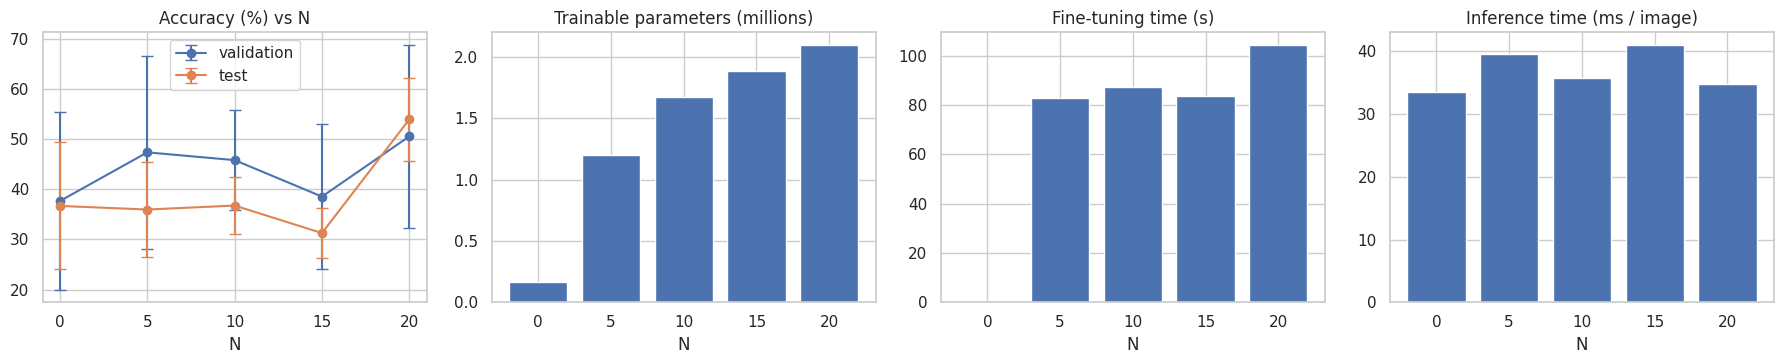

FLOPs per image are the same for every N: 599.3 MFLOPs.
Reading guide: parameters and training time grow with N; inference time and FLOPs do not (same network shape).
If the error bars overlap, the accuracy difference is NOT reliable.


In [15]:
g = sweepdf.groupby('N')
tableA = g[['trainable_params', 'val_acc', 'test_acc', 'test_f1', 'finetune_time_s', 'infer_ms', 'mflops']].mean().round(1)
tableA['test_acc_std'] = g['test_acc'].std().round(1)
display(tableA); tableA.to_csv('partA_summary.csv')

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8)); xs = [str(n) for n in LAYER_SETTINGS]
ax[0].errorbar(LAYER_SETTINGS, g['val_acc'].mean(), yerr=g['val_acc'].std(), marker='o', capsize=4, label='validation')
ax[0].errorbar(LAYER_SETTINGS, g['test_acc'].mean(), yerr=g['test_acc'].std(), marker='o', capsize=4, label='test')
ax[0].set_title('Accuracy (%) vs N'); ax[0].set_xlabel('N'); ax[0].legend()
ax[1].bar(xs, g['trainable_params'].mean() / 1e6); ax[1].set_title('Trainable parameters (millions)'); ax[1].set_xlabel('N')
ax[2].bar(xs, g['finetune_time_s'].mean());        ax[2].set_title('Fine-tuning time (s)');             ax[2].set_xlabel('N')
ax[3].bar(xs, g['infer_ms'].mean());               ax[3].set_title('Inference time (ms / image)');     ax[3].set_xlabel('N')
plt.tight_layout(); plt.show()
print('FLOPs per image are the same for every N:', round(sweepdf['mflops'].mean(), 1), 'MFLOPs.')
print('Reading guide: parameters and training time grow with N; inference time and FLOPs do not (same network shape).')
print('If the error bars overlap, the accuracy difference is NOT reliable.')

Best N by validation accuracy: 20 | N used for Part B and C: 20


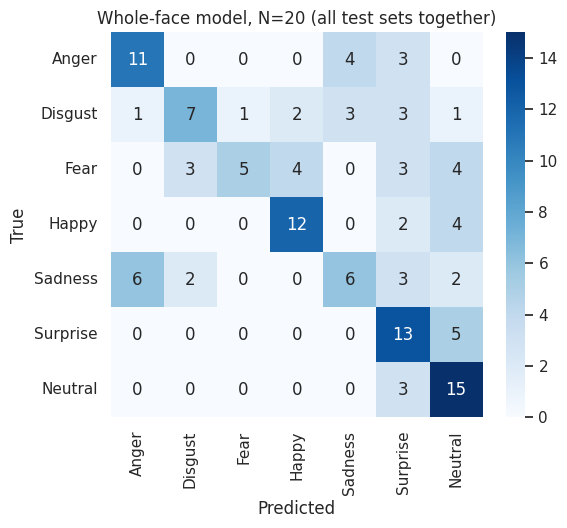

In [16]:
best_val_N = int(g['val_acc'].mean().idxmax())
CHOSEN_N = int(FORCE_N) if FORCE_N is not None else best_val_N
print('Best N by validation accuracy:', best_val_N, '| N used for Part B and C:', CHOSEN_N)
json.dump({'chosen_N': CHOSEN_N, 'first_frozen': FIRST_FROZEN}, open('chosen_config.json', 'w'))

yt = np.concatenate([sweep_preds[(s, CHOSEN_N)][0] for s in range(N_SPLITS)]); yp = np.concatenate([sweep_preds[(s, CHOSEN_N)][1] for s in range(N_SPLITS)])
plt.figure(figsize=(6, 5)); sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Whole-face model, N={CHOSEN_N} (all test sets together)'); plt.show()

In [17]:
def train_model(Xtr, ytr, Xva, yva, size, n_last, verbose=0):
    # stage 1 (head) + stage 2 (last N conv layers) in one call; returns model, history, timing
    model, backbone = build_model(size)
    t0 = time.time()
    set_trainable(backbone, 0); compile_model(model, WARMUP_LR)
    h1 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=WARMUP_EPOCHS, batch_size=BATCH_SIZE, verbose=verbose, callbacks=[stop(5)]).history
    h2 = {k: [] for k in h1}
    if n_last > 0:
        set_trainable(backbone, n_last); compile_model(model, FINETUNE_LR)
        h2 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=FINETUNE_EPOCHS, batch_size=BATCH_SIZE, verbose=verbose, callbacks=[stop(8)]).history
    hist = {k: h1[k] + h2[k] for k in h1}; hist['switch'] = len(h1['loss'])
    return model, hist, time.time() - t0

# ---- the three fusion rules. P has shape (images, 3 experts, 7 emotions) ----
def fuse_average(P):
    return P.mean(axis=1)

def conf_weights(P):
    c = P.max(axis=2)                                   # how sure is each expert?  (images, 3)
    return c / c.sum(axis=1, keepdims=True)

def fuse_confidence(P):
    return (conf_weights(P)[:, :, None] * P).sum(axis=1)

class WeightedSum(layers.Layer):                        # final = sum over experts of  weight x probabilities
    def call(self, inputs):
        w, p = inputs
        return tf.reduce_sum(w[:, :, None] * p, axis=1)

def gate_features(P):                                   # what the learned gate sees: all probabilities + each expert's confidence
    return np.concatenate([P.reshape(len(P), -1), P.max(axis=2)], axis=1).astype('float32')

def train_learned_gate(P_val, y_val):
    f_in, p_in = keras.Input((24,)), keras.Input((3, len(CLASS_NAMES)))
    w = layers.Dense(3, activation='softmax', kernel_initializer='zeros', kernel_regularizer=keras.regularizers.l2(1e-2))(f_in)   # starts as plain average
    gate = keras.Model([f_in, p_in], WeightedSum()([w, p_in]))
    gate.compile(optimizer=keras.optimizers.Adam(0.01), loss='sparse_categorical_crossentropy')
    gate.fit([gate_features(P_val), P_val], y_val, epochs=150, batch_size=16, verbose=0)
    return gate, keras.Model(f_in, w)                   # (full gate, model that outputs just the 3 weights)

print('Fusion functions ready.')

Fusion functions ready.


In [18]:
def make_condition(idx, hidden=None):
    # returns whole-face images and the 3 region crops; `hidden` = 0 eyes, 1 nose, 2 mouth, None = clean
    Xf = faces[idx].astype('float32'); Xr = [crops[idx, k].astype('float32') for k in range(3)]
    if hidden is not None:
        for j, i in enumerate(idx):
            x0, y0, x1, y1 = boxes[i, hidden]; Xf[j, y0:y1, x0:x1] = 127.5
        Xr[hidden][:] = 127.5
    return Xf, Xr

rows, gate_rows, cost_rows, curves = [], [], [], {}
for s in range(N_SPLITS):
    seed = SEED + s; tr, va, te = make_split(seed); gc.collect(); keras.utils.set_random_seed(seed)
    print(f'\n=== split {s + 1}/{N_SPLITS} | test persons: {sorted(set(persons[te]))} ===')

    # ---- train 4 models: whole face + 3 experts ----
    models, times = {}, {}
    models['face'], h, times['face'] = train_model(faces[tr].astype('float32'), y[tr], faces[va].astype('float32'), y[va], FACE_SIZE, CHOSEN_N)
    curves[(s, 'face')] = h; print(f"  whole face : val acc {max(h['val_accuracy'])*100:5.1f}% | {len(h['loss'])} epochs | {times['face']:5.1f}s")
    for k, name in enumerate(REGIONS):
        models[name], h, times[name] = train_model(crops[tr, k].astype('float32'), y[tr], crops[va, k].astype('float32'), y[va], REGION_SIZE, CHOSEN_N)
        curves[(s, name)] = h; print(f"  {name:<11}: val acc {max(h['val_accuracy'])*100:5.1f}% | {len(h['loss'])} epochs | {times[name]:5.1f}s")

    # ---- learned gate: trained on the VALIDATION predictions of the (frozen) experts ----
    Xf, Xr = make_condition(va)
    P_val = np.stack([models[n].predict(Xr[k], verbose=0) for k, n in enumerate(REGIONS)], axis=1)
    gate, gate_w = train_learned_gate(P_val, y[va])

    # ---- evaluate every method on the 4 test conditions ----
    for cond, hidden in zip(COND_NAMES, [None, 0, 1, 2]):
        Xf, Xr = make_condition(te, hidden)
        P = np.stack([models[n].predict(Xr[k], verbose=0) for k, n in enumerate(REGIONS)], axis=1)
        results = {'Whole-face model': models['face'].predict(Xf, verbose=0),
                   'Eyes only': P[:, 0], 'Nose only': P[:, 1], 'Mouth only': P[:, 2],
                   'Average': fuse_average(P), 'Confidence gate': fuse_confidence(P),
                   'Learned gate': gate.predict([gate_features(P), P], verbose=0)}
        for method, prob in results.items():
            rows.append(dict(split=s, condition=cond, method=method, acc=accuracy_score(y[te], prob.argmax(1)) * 100,
                             f1=f1_score(y[te], prob.argmax(1), average='macro') * 100))
        for gname, w in [('Confidence gate', conf_weights(P)), ('Learned gate', gate_w.predict(gate_features(P), verbose=0))]:
            gate_rows.append(dict(split=s, condition=cond, gate=gname, **dict(zip(REGIONS, w.mean(axis=0)))))

    # ---- cost of whole-face model vs the 3 experts together ----
    ex = [models[n] for n in REGIONS]
    cost_rows.append(dict(split=s,
        face_train_params=count_trainable(models['face']), moe_train_params=sum(count_trainable(m) for m in ex),
        face_time_s=times['face'], moe_time_s=sum(times[n] for n in REGIONS),
        face_mflops=get_mflops(models['face']), moe_mflops=sum(get_mflops(m) for m in ex),
        face_ms=get_infer_ms(models['face'], faces[te]), moe_ms=sum(get_infer_ms(m, crops[te, k]) for k, m in enumerate(ex))))
    del models, gate, gate_w

res = pd.DataFrame(rows); res.to_csv('partB_C_all_results.csv', index=False)
print('\nDone. All models trained and evaluated.')


=== split 1/3 | test persons: [np.str_('KL'), np.str_('UY')] ===
  whole face : val acc  73.8% | 40 epochs | 236.1s
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  eyes       : val acc  50.0% | 44 epochs | 116.6s
  nose       : val acc  26.2% | 27 epochs |  84.3s
  mouth      : val acc  57.1% | 23 epochs |  73.1s

=== split 2/3 | test persons: [np.str_('KR'), np.str_('YM')] ===
  whole face : val acc  47.6% | 33 epochs | 226.2s
  eyes       : val acc  61.9% | 40 epochs | 102.6s
  nose       : val acc  38.1% | 34 epochs |  85.0s
  mouth      : val acc  31.0% | 18 epochs |  57.7s

=== split 3/3 | test persons: [np.str_('KM'), np.str_('TM')] ===
  whole face : val acc  37.5% | 19 epochs | 119.3s
  eyes       : val acc  42.5% | 42 epochs | 102.5s
  nose       : val acc  27.5% | 21 epochs |  59.7s
  mouth      : val acc  40.0% | 29 epochs |  74.1s

Done. All models trained and evaluated.


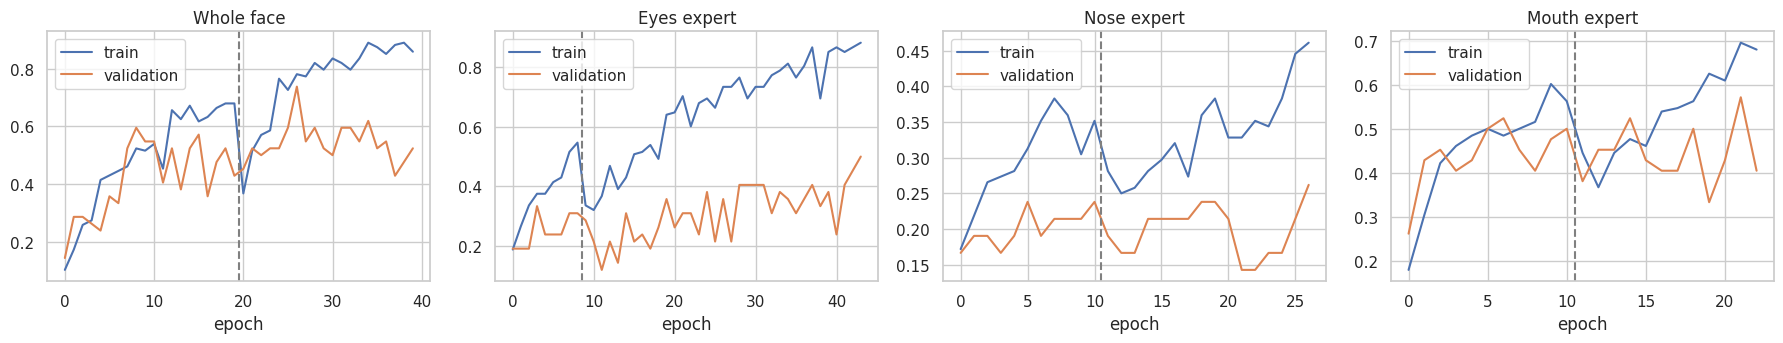

In [19]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, name in zip(ax, ['face'] + REGIONS):
    h = curves[(0, name)]
    a.plot(h['accuracy'], label='train'); a.plot(h['val_accuracy'], label='validation')
    a.axvline(h['switch'] - 0.5, color='gray', ls='--'); a.set_title('Whole face' if name == 'face' else f'{name.capitalize()} expert'); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

acc          f1      
                  mean   std  mean   std
method                                  
Eyes only         32.1  11.8  25.4  12.3
Nose only         21.2  13.3  13.7  10.6
Mouth only        31.3   2.9  28.1   3.8
Whole-face model  43.0   6.0  40.4   3.7
Average           39.1   4.7  34.4   3.0
Confidence gate   39.1   4.7  34.0   3.3
Learned gate      39.1   3.7  34.5   3.6

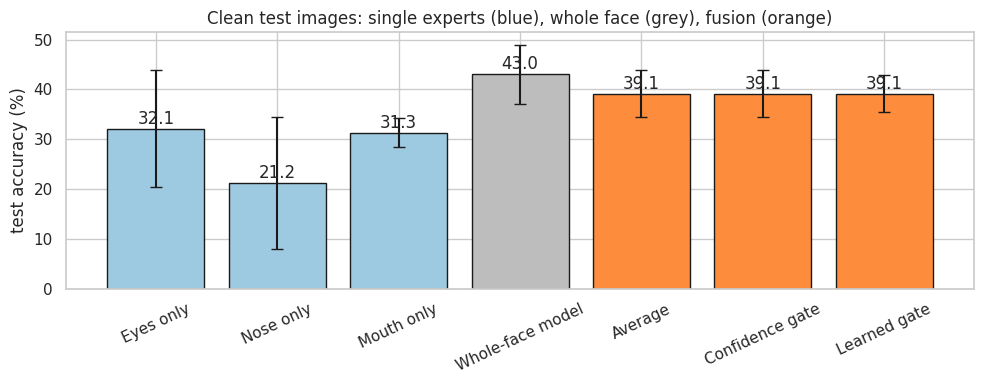

In [20]:
clean = res[res.condition == 'Clean'].groupby('method')[['acc', 'f1']].agg(['mean', 'std']).round(1)
order = ['Eyes only', 'Nose only', 'Mouth only', 'Whole-face model', 'Average', 'Confidence gate', 'Learned gate']
clean = clean.loc[order]; display(clean)

m = clean[('acc', 'mean')]; sd = clean[('acc', 'std')]
cols = ['#9ecae1'] * 3 + ['#bdbdbd'] + ['#fd8d3c'] * 3
plt.figure(figsize=(10, 4)); plt.bar(order, m, yerr=sd, capsize=4, color=cols, edgecolor='k')
for i, v in enumerate(m): plt.text(i, v + 1, f'{v:.1f}', ha='center')
plt.ylabel('test accuracy (%)'); plt.xticks(rotation=25); plt.title('Clean test images: single experts (blue), whole face (grey), fusion (orange)')
plt.tight_layout(); plt.show()

In [2]:
# c = pd.DataFrame(cost_rows).mean().round(1)
# costtab = pd.DataFrame({'Whole-face model': [c.face_train_params, c.face_time_s, c.face_mflops, c.face_ms],
#                         '3 experts together': [c.moe_train_params, c.moe_time_s, c.moe_mflops, c.moe_ms]},
#                        index=['Trainable params', 'Training time (s)', 'FLOPs (MFLOPs / image)', 'Inference (ms / image)'])
# display(costtab); costtab.to_csv('partB_cost_table.csv')
# print('The 3 experts use small 128px crops, so their FLOPs can be lower than one 224px whole-face model, but you train 3 models.')

In [3]:
# methods = ['Whole-face model', 'Average', 'Confidence gate', 'Learned gate']
# rob = res[res.method.isin(methods)].groupby(['method', 'condition']).acc.agg(['mean', 'std']).reset_index()
# tab = rob.pivot(index='method', columns='condition', values='mean').loc[methods, COND_NAMES].round(1)
# tab['Average of hidden'] = tab[COND_NAMES[1:]].mean(axis=1).round(1)
# display(tab); tab.to_csv('partC_robustness_table.csv')

# fig, ax = plt.subplots(figsize=(11, 4.5)); w = 0.2
# for j, mth in enumerate(methods):
#     d = rob[rob.method == mth].set_index('condition').loc[COND_NAMES]
#     ax.bar(np.arange(4) + (j - 1.5) * w, d['mean'], w, yerr=d['std'], capsize=3, label=mth, edgecolor='k')
# ax.set_xticks(range(4)); ax.set_xticklabels(COND_NAMES); ax.set_ylabel('test accuracy (%)'); ax.legend()
# ax.set_title('Accuracy when a region is hidden at test time (mean ± std over splits)'); plt.tight_layout(); plt.show()

In [1]:
# gw = pd.DataFrame(gate_rows).groupby(['gate', 'condition'])[REGIONS].mean().round(2)
# display(gw)

# fig, ax = plt.subplots(1, 2, figsize=(13, 4))
# for a, gname in zip(ax, ['Confidence gate', 'Learned gate']):
#     d = gw.loc[gname].loc[COND_NAMES]
#     d.plot(kind='bar', ax=a, color=['tab:blue', 'tab:green', 'tab:red'], edgecolor='k', rot=15)
#     a.axhline(1 / 3, color='k', ls='--', lw=1); a.set_ylim(0, 1); a.set_ylabel('weight'); a.set_title(f'{gname}: weight of each expert')
# plt.tight_layout(); plt.show()
# print('Dashed line = equal weight (1/3). When the eyes are hidden, a good gate lowers the blue bar (and so on).')

In [24]:
print('==================== FINAL SUMMARY ====================')
print(f'Part A: N chosen = {CHOSEN_N} (last {CHOSEN_N} of 52 conv layers fine-tuned; first {FIRST_FROZEN} always frozen)')
print(f'        whole-face test accuracy at that N : {tableA.loc[CHOSEN_N, "test_acc"]} % (std {tableA.loc[CHOSEN_N, "test_acc_std"]})')
print('Part B: clean test accuracy (mean over splits)')
print(clean[('acc', 'mean')].to_string())
print('Part C: accuracy when a region is hidden')
display(tab)
print('\nSaved files: partA_summary.csv, partA_all_runs.csv, partB_cost_table.csv, partB_C_all_results.csv, partC_robustness_table.csv, chosen_config.json')
print('Remember: JAFFE has ~10 people, so differences of a few points are within noise. Always quote the std.')

==================== FINAL SUMMARY ====================
Part A: N chosen = 20 (last 20 of 52 conv layers fine-tuned; first 10 always frozen)
        whole-face test accuracy at that N : 53.9 % (std 8.2)
Part B: clean test accuracy (mean over splits)
method
Eyes only           32.1
Nose only           21.2
Mouth only          31.3
Whole-face model    43.0
Average             39.1
Confidence gate     39.1
Learned gate        39.1
Part C: accuracy when a region is hidden


condition,Clean,Eyes hidden,Nose hidden,Mouth hidden,Average of hidden
method,,,,,
Whole-face model,43.0,25.8,22.6,23.4,23.9
Average,39.1,25.8,34.4,35.2,31.8
Confidence gate,39.1,21.9,36.0,34.4,30.8
Learned gate,39.1,16.4,39.1,34.4,30.0



Saved files: partA_summary.csv, partA_all_runs.csv, partB_cost_table.csv, partB_C_all_results.csv, partC_robustness_table.csv, chosen_config.json
Remember: JAFFE has ~10 people, so differences of a few points are within noise. Always quote the std.
